# Atividade de Machine Learning: classificação e regressão

**Aluno:** Vinicius

## 1. Introdução

Este notebook resolve dois problemas clássicos de aprendizado supervisionado usando Python e scikit-learn:

- **Parte 1 – Classificação:** prever se um tumor de mama é **benigno** ou **maligno** a partir de medidas extraídas de exames (dataset *Breast Cancer Wisconsin*).
- **Parte 2 – Regressão:** prever o **preço de imóveis** na Califórnia com Regressão Linear (dataset *California Housing*).

As duas partes seguem o mesmo roteiro: carregar os dados, olhar para eles antes de modelar, preparar, treinar, avaliar e só então tirar conclusões. No final há uma conclusão geral comparando o que funcionou bem e o que não funcionou nos dois casos.

Algumas escolhas que valem para o notebook todo:

- uso uma semente fixa (`SEED = 42`) para que os números citados nos textos sejam os mesmos a cada execução;
- o conjunto de teste é separado logo no início e só é usado na avaliação final, nunca para tomar decisões sobre o modelo;
- todos os gráficos usam tema escuro, configurado uma única vez logo depois dos imports.

## 2. Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import (train_test_split, cross_validate,
                                     cross_val_score, StratifiedKFold, KFold)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

SEED = 42  # semente usada em tudo que envolve sorteio

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

In [2]:
# Tema escuro dos gráficos, definido uma vez só para o notebook inteiro
FUNDO, PAINEL, GRADE, TEXTO = "#0f1117", "#161a23", "#2b303b", "#e6e6e6"
AZUL, ROSA, AMARELO, VERDE = "#4cc9f0", "#f72585", "#ffd166", "#06d6a0"

plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": FUNDO,
    "savefig.facecolor": FUNDO,
    "axes.facecolor": PAINEL,
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.6,
    "text.color": TEXTO,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "legend.facecolor": PAINEL,
    "legend.edgecolor": GRADE,
    "figure.dpi": 110,
})
sns.set_palette([AZUL, ROSA, AMARELO, VERDE])

# cores fixas para as classes da Parte 1
CORES_CLASSE = {"benigno": AZUL, "maligno": ROSA}

---

# Parte 1 – Classificação de diagnóstico de câncer de mama

## 3. Carregamento dos dados

O *Breast Cancer Wisconsin (Diagnostic)* já vem com o scikit-learn. Cada linha é um exame: uma amostra de tecido da mama foi digitalizada e, para os núcleos das células que aparecem na imagem, foram calculadas dez medidas (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal). Para cada medida o dataset guarda a **média**, o **erro padrão** e o **pior valor** (média dos três maiores), o que dá 30 atributos numéricos.

In [3]:
dados_cancer = load_breast_cancer(as_frame=True)
df_cancer = dados_cancer.frame.copy()

# No scikit-learn o alvo vem codificado como 0 = maligno e 1 = benigno.
# Crio uma coluna com o nome da classe para a análise ficar mais legível.
df_cancer["diagnostico"] = df_cancer["target"].map({0: "maligno", 1: "benigno"})

df_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnostico
0,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119,0,maligno
1,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089,0,maligno
2,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088,0,maligno
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,0,maligno
4,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077,0,maligno


## 4. Análise exploratória

### 4.1 Tamanho do dataset e qualidade dos dados

In [4]:
n_registros, n_atributos = dados_cancer.data.shape

print(f"Quantidade de registros : {n_registros}")
print(f"Quantidade de atributos : {n_atributos} (mais a coluna alvo)")
print(f"Tipos dos atributos     : {dados_cancer.data.dtypes.unique().tolist()}")
print(f"Valores ausentes        : {int(df_cancer.isna().sum().sum())}")
print(f"Linhas duplicadas       : {int(dados_cancer.data.duplicated().sum())}")

Quantidade de registros : 569
Quantidade de atributos : 30 (mais a coluna alvo)
Tipos dos atributos     : [dtype('float64')]
Valores ausentes        : 0
Linhas duplicadas       : 0


### 4.2 Distribuição das classes

,quantidade,percentual (%)
diagnostico,,
benigno,357,62.700
maligno,212,37.300


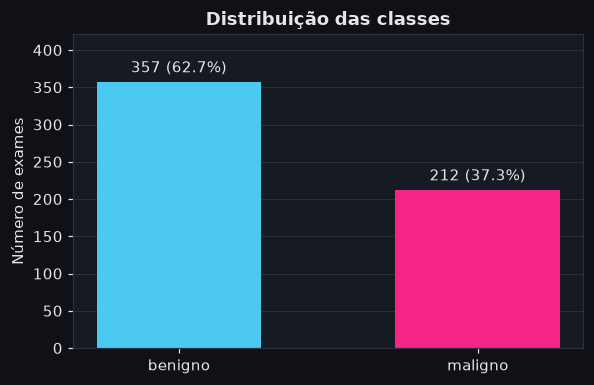

In [5]:
contagem = df_cancer["diagnostico"].value_counts()
distribuicao = pd.DataFrame({
    "quantidade": contagem,
    "percentual (%)": (contagem / n_registros * 100).round(1),
})
display(distribuicao)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
barras = ax.bar(contagem.index, contagem.values,
                color=[CORES_CLASSE[c] for c in contagem.index], width=0.55)
ax.bar_label(barras, labels=[f"{v} ({v / n_registros:.1%})" for v in contagem.values],
             padding=4)
ax.set_title("Distribuição das classes")
ax.set_ylabel("Número de exames")
ax.set_ylim(0, contagem.max() * 1.18)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

São 357 exames benignos (62,7%) e 212 malignos (37,3%). Existe um desbalanceamento, mas ele é moderado, então não vi necessidade de técnicas de reamostragem. Mesmo assim ele traz duas consequências práticas:

- um modelo que respondesse "benigno" para tudo já acertaria 62,7% das vezes, então esse é o piso com o qual qualquer *accuracy* deve ser comparada;
- vale a pena estratificar a divisão treino/teste, para que os dois conjuntos mantenham essa mesma proporção.

### 4.3 Estatísticas descritivas

In [6]:
# Transposto para caberem os 30 atributos, um por linha
df_cancer[dados_cancer.feature_names].describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.000,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.000,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.000,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.000,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.000,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.000,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.000,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.000,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.000,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.000,0.063,0.007,0.050,0.058,0.062,0.066,0.097


Não há valores ausentes nem linhas duplicadas, e todos os atributos são numéricos contínuos, então não é preciso tratar categorias nem imputar dados.

O que mais chama atenção na tabela é a diferença de escala: `mean area` tem média perto de 655 e chega a 2.501, `worst area` passa de 4.000, enquanto `mean smoothness` gira em torno de 0,096 e `fractal dimension error` em torno de 0,004. São várias ordens de grandeza de diferença. Para algoritmos baseados em distância (KNN) ou em otimização com regularização (Regressão Logística) isso é um problema, porque os atributos de maior escala dominariam o resultado só por serem números grandes. É o motivo da padronização na etapa de pré-processamento.

Também dá para ver que os atributos de área e os de erro padrão são assimétricos: em `area error`, por exemplo, o máximo (542) está muito acima do terceiro quartil (45).

### 4.4 Como os atributos se relacionam com o diagnóstico

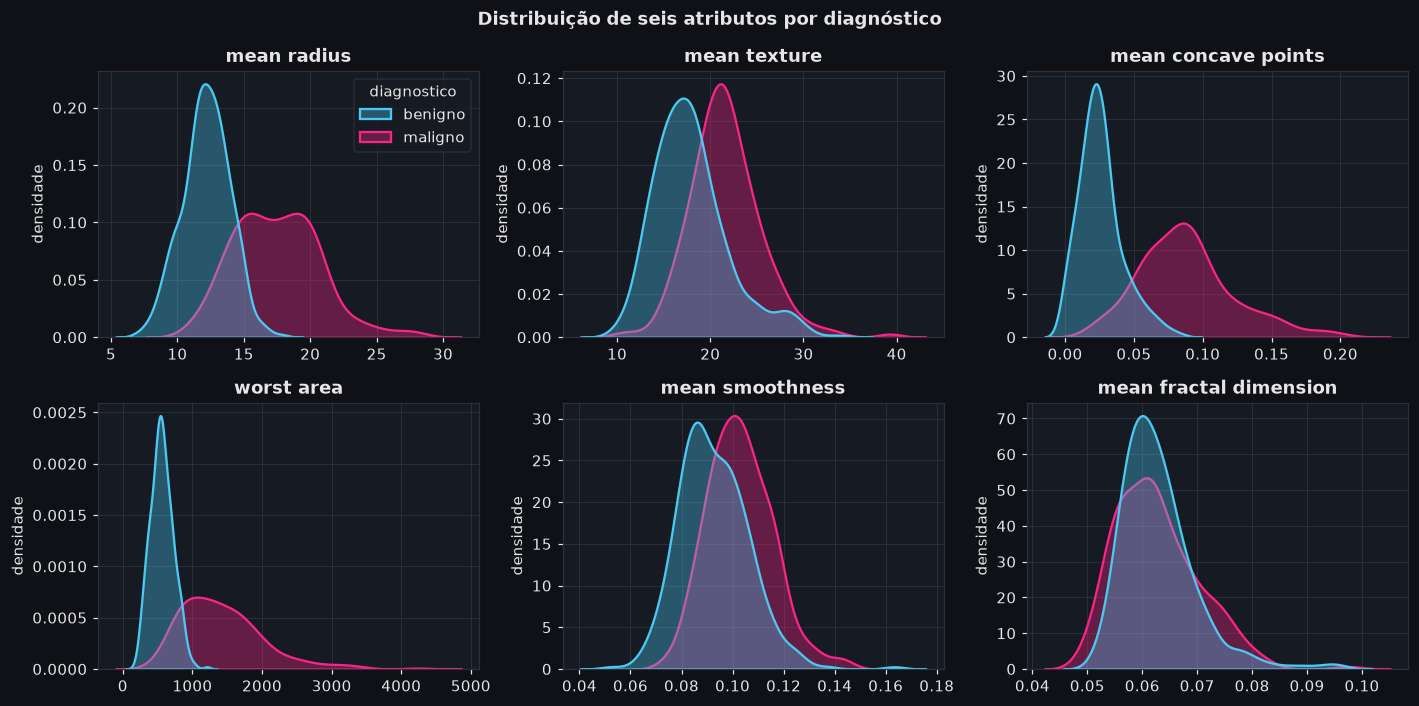

In [7]:
# Distribuição de alguns atributos separada por classe
atributos_exemplo = ["mean radius", "mean texture", "mean concave points",
                     "worst area", "mean smoothness", "mean fractal dimension"]

fig, eixos = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, atributo in zip(eixos.ravel(), atributos_exemplo):
    sns.kdeplot(data=df_cancer, x=atributo, hue="diagnostico", hue_order=["benigno", "maligno"],
                palette=CORES_CLASSE, fill=True, alpha=0.35, common_norm=False,
                linewidth=1.5, ax=ax, legend=(atributo == atributos_exemplo[0]))
    ax.set_title(atributo)
    ax.set_xlabel("")
    ax.set_ylabel("densidade")
fig.suptitle("Distribuição de seis atributos por diagnóstico", fontweight="bold")
plt.tight_layout()
plt.show()

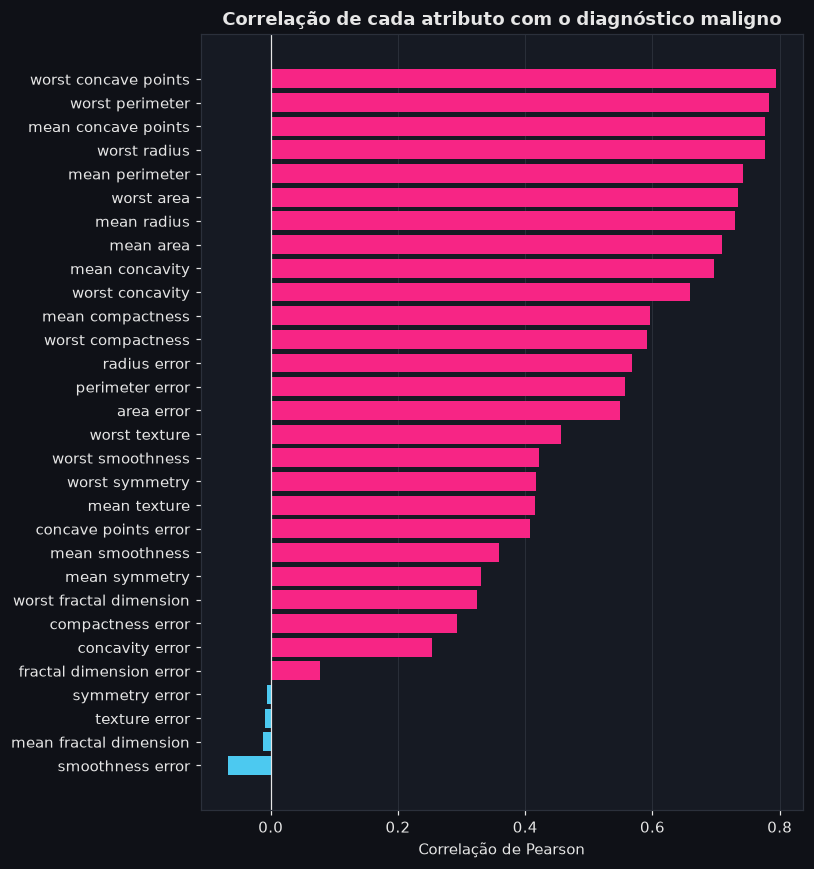

In [8]:
# Correlação de cada atributo com o tumor ser maligno (1 = maligno aqui)
eh_maligno = (df_cancer["target"] == 0).astype(int)
corr_alvo = (df_cancer[dados_cancer.feature_names]
             .corrwith(eh_maligno)
             .sort_values())

fig, ax = plt.subplots(figsize=(7.5, 8))
ax.barh(corr_alvo.index, corr_alvo.values,
        color=[ROSA if v > 0 else AZUL for v in corr_alvo.values])
ax.axvline(0, color=TEXTO, linewidth=0.8)
ax.set_title("Correlação de cada atributo com o diagnóstico maligno")
ax.set_xlabel("Correlação de Pearson")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

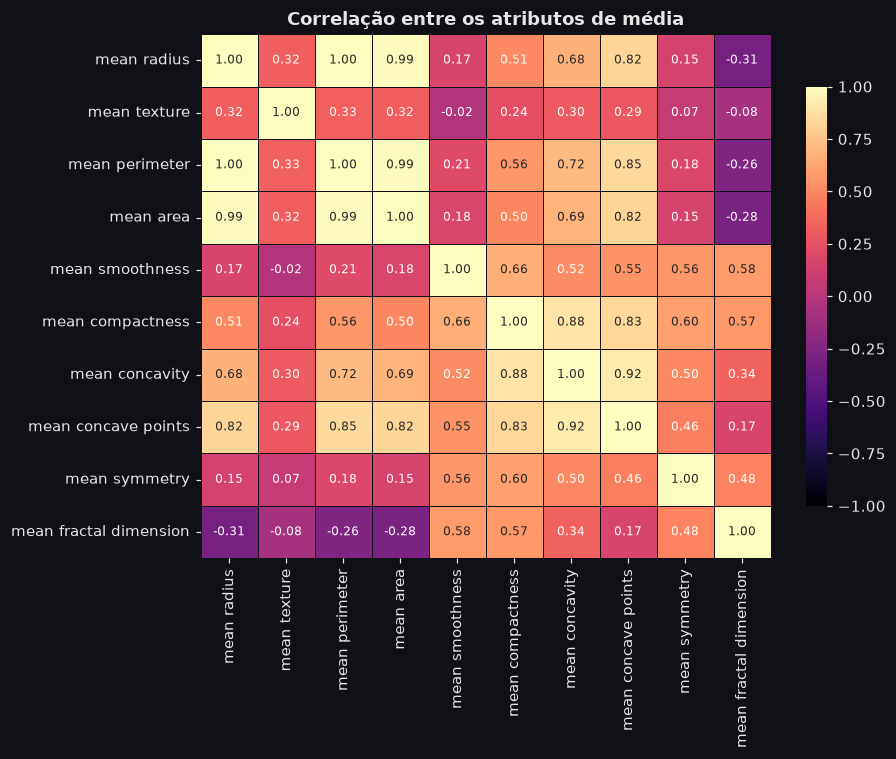

In [9]:
# Correlação entre os dez atributos de média, para ver redundância entre eles
colunas_media = [c for c in dados_cancer.feature_names if c.startswith("mean ")]

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(df_cancer[colunas_media].corr(), annot=True, fmt=".2f", cmap="magma",
            vmin=-1, vmax=1, linewidths=0.5, linecolor=FUNDO,
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlação entre os atributos de média")
ax.grid(False)
plt.tight_layout()
plt.show()

Algumas observações a partir dos três gráficos:

- **Os tumores malignos são, em geral, maiores e mais irregulares.** O raio médio dos malignos é 17,5 contra 12,1 dos benignos, e as curvas de `mean radius`, `mean concave points` e `worst area` ficam bem separadas entre as classes.
- **Nem todo atributo ajuda.** As curvas de `mean fractal dimension` praticamente se sobrepõem, e a correlação dele com o diagnóstico é quase zero (-0,01). `mean smoothness` e `mean texture` separam só um pouco.
- **Os atributos mais associados ao diagnóstico maligno** são `worst concave points` (0,79), `worst perimeter` (0,78), `mean concave points` (0,78) e `worst radius` (0,78). Nenhum atributo tem correlação negativa relevante com malignidade.
- **Há muita redundância.** Raio, perímetro e área medem basicamente a mesma coisa (tamanho): a correlação entre `mean radius` e `mean perimeter` é 0,998, e com `mean area` é 0,987. Concavidade e pontos côncavos também andam juntos (0,92).

Essa redundância (multicolinearidade) não costuma atrapalhar a capacidade de previsão, mas torna a interpretação individual dos coeficientes de um modelo linear menos confiável. Volto a esse ponto na avaliação.

## 5. Pré-processamento

Três decisões aqui:

1. **Alvo.** O scikit-learn codifica benigno como 1. Como o que interessa clinicamente é encontrar o tumor maligno, eu inverto a codificação e passo a tratar **maligno = 1 (classe positiva)**. Assim *precision*, *recall* e *F1* passam a responder perguntas sobre os casos malignos, que é o que importa.
2. **Divisão treino/teste.** 80% para treino e 20% para teste, com estratificação para manter a proporção das classes nos dois conjuntos.
3. **Padronização.** Como as escalas são muito diferentes, uso `StandardScaler`. Ele fica dentro de um *pipeline* junto com o modelo, de modo que a média e o desvio padrão são calculados só com os dados de treino. Se eu padronizasse tudo antes de dividir, informação do teste vazaria para o treino.

In [10]:
# Variáveis independentes (X) e variável alvo (y), com maligno = 1
X_cancer = dados_cancer.data
y_cancer = (dados_cancer.target == 0).astype(int).rename("maligno")

X_treino_c, X_teste_c, y_treino_c, y_teste_c = train_test_split(
    X_cancer, y_cancer, test_size=0.20, stratify=y_cancer, random_state=SEED
)

print(f"Treino: {X_treino_c.shape[0]} exames | proporção de malignos: {y_treino_c.mean():.1%}")
print(f"Teste : {X_teste_c.shape[0]} exames | proporção de malignos: {y_teste_c.mean():.1%}")

Treino: 455 exames | proporção de malignos: 37.4%
Teste : 114 exames | proporção de malignos: 36.8%


## 6. Treinamento do modelo

### 6.1 Escolha do algoritmo

O enunciado pede um entre quatro algoritmos. Em vez de escolher no escuro, comparo os quatro com validação cruzada de 5 partes **usando apenas o conjunto de treino** (o teste continua guardado). Incluo também um classificador "ingênuo", que sempre responde a classe mais frequente, para ter uma referência do que seria não aprender nada.

In [11]:
candidatos = {
    "Referência (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

linhas = []
for nome, modelo in candidatos.items():
    notas = cross_validate(modelo, X_treino_c, y_treino_c, cv=cv_c,
                           scoring=["accuracy", "recall", "f1"])
    linhas.append({
        "modelo": nome,
        "accuracy": notas["test_accuracy"].mean(),
        "desvio (accuracy)": notas["test_accuracy"].std(),
        "recall (maligno)": notas["test_recall"].mean(),
        "f1 (maligno)": notas["test_f1"].mean(),
    })

comparacao = pd.DataFrame(linhas).set_index("modelo")
comparacao

,accuracy,desvio (accuracy),recall (maligno),f1 (maligno)
modelo,,,,
Referência (classe mais frequente),0.626,0.000,0.000,0.000
Regressão Logística,0.974,0.015,0.953,0.964
Árvore de Decisão,0.923,0.033,0.894,0.896
Random Forest,0.963,0.015,0.935,0.949
KNN (k=5),0.965,0.019,0.918,0.951


Leitura da tabela:

- Todos os quatro algoritmos ficam muito acima da referência (62,6% de *accuracy* e 0 de *recall*, já que ela nunca prevê maligno), ou seja, os atributos realmente carregam informação sobre o diagnóstico.
- A **Regressão Logística** teve a melhor média nas três métricas: 97,4% de *accuracy*, 95,3% de *recall* e 96,4% de F1.
- Random Forest (96,3%) e KNN (96,5%) ficaram logo atrás em *accuracy*. Como o desvio padrão entre as partes é de cerca de 1,5 ponto percentual, **essa diferença é pequena demais para afirmar que a Regressão Logística é de fato superior**; os três estão tecnicamente empatados.
- A Árvore de Decisão sozinha foi a mais fraca (92,3%) e a mais instável (desvio de 3,3 pontos).

Fico com a **Regressão Logística** por três motivos: teve o maior *recall* para a classe maligna, que é a métrica mais importante neste problema; é o modelo mais simples dos três empatados; e os coeficientes permitem ver o que pesou na decisão.

### 6.2 Treinamento do modelo escolhido

In [12]:
modelo_cancer = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)
modelo_cancer.fit(X_treino_c, y_treino_c)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 7. Avaliação dos resultados

Agora sim uso o conjunto de teste, que o modelo nunca viu.

In [13]:
pred_treino_c = modelo_cancer.predict(X_treino_c)
pred_teste_c = modelo_cancer.predict(X_teste_c)

metricas_c = pd.DataFrame({
    "treino": [accuracy_score(y_treino_c, pred_treino_c),
               precision_score(y_treino_c, pred_treino_c),
               recall_score(y_treino_c, pred_treino_c),
               f1_score(y_treino_c, pred_treino_c)],
    "teste": [accuracy_score(y_teste_c, pred_teste_c),
              precision_score(y_teste_c, pred_teste_c),
              recall_score(y_teste_c, pred_teste_c),
              f1_score(y_teste_c, pred_teste_c)],
}, index=["Accuracy", "Precision (maligno)", "Recall (maligno)", "F1-Score (maligno)"])

metricas_c.style.format("{:.4f}")

,treino,teste
Accuracy,0.9868,0.9649
Precision (maligno),1.0000,0.9750
Recall (maligno),0.9647,0.9286
F1-Score (maligno),0.9820,0.9512


In [14]:
# Relatório completo, com as métricas das duas classes
print(classification_report(y_teste_c, pred_teste_c,
                            target_names=["benigno", "maligno"], digits=4))

              precision    recall  f1-score   support

     benigno     0.9595    0.9861    0.9726        72
     maligno     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



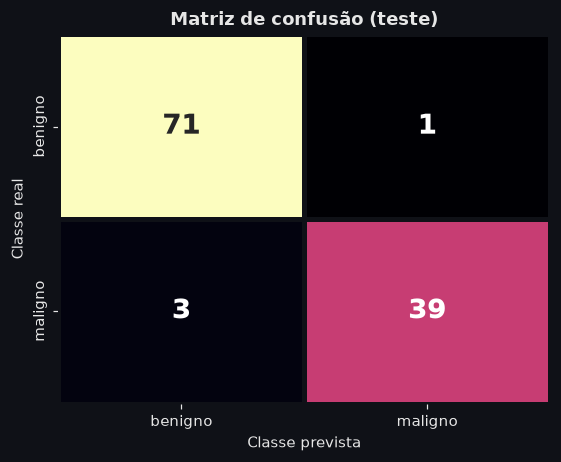

Verdadeiros negativos (benigno previsto como benigno): 71
Falsos positivos      (benigno previsto como maligno): 1
Falsos negativos      (maligno previsto como benigno): 3
Verdadeiros positivos (maligno previsto como maligno): 39


In [15]:
matriz = confusion_matrix(y_teste_c, pred_teste_c)
vn, fp, fn, vp = matriz.ravel()

fig, ax = plt.subplots(figsize=(5.2, 4.3))
sns.heatmap(matriz, annot=True, fmt="d", cmap="magma", cbar=False,
            linewidths=2, linecolor=FUNDO, annot_kws={"size": 18, "weight": "bold"},
            xticklabels=["benigno", "maligno"], yticklabels=["benigno", "maligno"], ax=ax)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de confusão (teste)")
ax.grid(False)
plt.tight_layout()
plt.show()

print(f"Verdadeiros negativos (benigno previsto como benigno): {vn}")
print(f"Falsos positivos      (benigno previsto como maligno): {fp}")
print(f"Falsos negativos      (maligno previsto como benigno): {fn}")
print(f"Verdadeiros positivos (maligno previsto como maligno): {vp}")

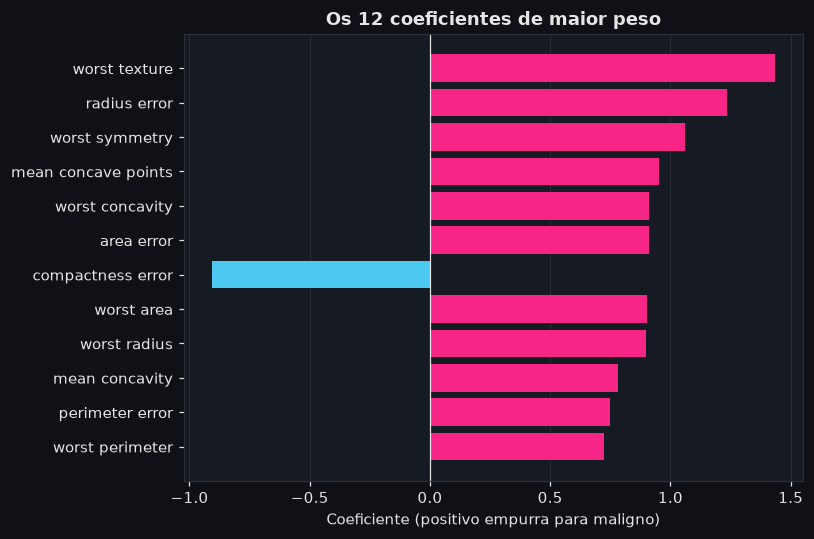

In [16]:
# O que o modelo aprendeu: coeficientes da regressão logística.
# Como os dados foram padronizados, os coeficientes são comparáveis entre si.
coeficientes_c = pd.Series(modelo_cancer[-1].coef_[0], index=X_cancer.columns)
mais_fortes = coeficientes_c.reindex(coeficientes_c.abs().sort_values().index).tail(12)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(mais_fortes.index, mais_fortes.values,
        color=[ROSA if v > 0 else AZUL for v in mais_fortes.values])
ax.axvline(0, color=TEXTO, linewidth=0.8)
ax.set_title("Os 12 coeficientes de maior peso")
ax.set_xlabel("Coeficiente (positivo empurra para maligno)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 7.1 Análise dos resultados

**Desempenho geral.** No conjunto de teste (114 exames) o modelo acertou 110, o que dá **96,5% de *accuracy***, bem acima dos 62,7% que se obteria respondendo sempre "benigno". No treino a *accuracy* foi 98,7%. A diferença de cerca de 2 pontos entre treino e teste é pequena e o resultado do teste está dentro do que a validação cruzada indicava (97,4% ± 1,5), então não há sinal de sobreajuste relevante.

**Olhando para a classe maligna:**

- ***Precision* = 97,5%:** das 40 vezes em que o modelo disse "maligno", acertou 39. Só 1 paciente com tumor benigno receberia um alarme falso.
- ***Recall* = 92,9%:** dos 42 tumores malignos do teste, o modelo encontrou 39 e **deixou passar 3**.
- **F1 = 95,1%**, o equilíbrio entre as duas.

**Os erros não têm o mesmo peso.** O falso positivo gera ansiedade e um exame a mais; o falso negativo é um câncer que deixaria de ser tratado. Por isso, apesar de a *accuracy* ser alta, o número que mais me preocupa é o *recall*: 3 casos perdidos em 42 é cerca de 7%, o que seria inaceitável para um uso clínico sem revisão humana.

A tabela abaixo mostra os quatro exames em que o modelo errou, com a probabilidade de malignidade que ele calculou para cada um.

In [17]:
prob_maligno = modelo_cancer.predict_proba(X_teste_c)[:, 1]

erros = pd.DataFrame({
    "classe real": y_teste_c.map({0: "benigno", 1: "maligno"}),
    "classe prevista": pd.Series(pred_teste_c, index=y_teste_c.index).map({0: "benigno", 1: "maligno"}),
    "probabilidade de maligno": prob_maligno,
})[pred_teste_c != y_teste_c]

erros.sort_values("probabilidade de maligno")

,classe real,classe prevista,probabilidade de maligno
73,maligno,benigno,0.061
190,maligno,benigno,0.315
205,maligno,benigno,0.492
455,benigno,maligno,0.509


Dois dos quatro erros são casos de fronteira, com probabilidade praticamente em cima do limiar de 0,5 (0,509 no falso positivo e 0,492 em um dos falsos negativos). Um terceiro falso negativo recebeu 0,315. Baixar o limiar de decisão recuperaria esses dois casos em troca de mais alarmes falsos, uma troca que faz sentido em triagem. Não fiz esse ajuste aqui porque escolher o limiar olhando para o conjunto de teste seria usar o teste para tomar decisão; o correto seria definir o limiar com validação no treino.

O quarto erro é mais incômodo: um tumor maligno ao qual o modelo atribuiu apenas 6% de probabilidade. Nesse caso não há ajuste de limiar razoável que resolva, o que mostra que existem tumores malignos com medidas muito parecidas com as de tumores benignos.

**Sobre os coeficientes.** Os maiores pesos positivos estão em `worst texture`, `radius error`, `worst symmetry`, `mean concave points` e nas medidas de tamanho e concavidade, o que é coerente com a análise exploratória: tumores maiores, com textura mais heterogênea e contornos mais irregulares tendem a ser malignos. Já o coeficiente negativo de `compactness error` deve ser lido com cuidado: sozinho esse atributo tem correlação *positiva* com malignidade (0,29). O sinal invertido é efeito da multicolinearidade apontada antes, em que o modelo compensa um atributo com outro muito parecido. Os coeficientes servem para ter uma ideia geral do que importa, não para tirar conclusões sobre cada atributo isoladamente.

**Limitações desta avaliação.** O conjunto de teste tem só 114 exames, dos quais 42 malignos. Cada tumor maligno a mais ou a menos muda o *recall* em 2,4 pontos percentuais, então a diferença entre os 92,9% do teste e os 95,3% da validação cruzada equivale a um único exame. Os números são uma boa estimativa, mas com uma margem de incerteza considerável.

---

# Parte 2 – Regressão Linear para previsão de preços de imóveis

## 8. Carregamento dos dados

Escolhi o *California Housing*, uma das sugestões do enunciado. Ele vem do censo dos Estados Unidos de 1990 e tem um detalhe importante: **cada linha não é uma casa, e sim um quarteirão censitário** (*block group*), a menor unidade para a qual o censo publica dados, normalmente com 600 a 3.000 moradores.

| Coluna | Significado |
|---|---|
| `MedInc` | renda mediana dos moradores do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana dos imóveis (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude`, `Longitude` | localização do quarteirão |
| `MedHouseVal` | **valor mediano dos imóveis, em centenas de milhares de dólares (alvo)** |

Na primeira execução o scikit-learn baixa o arquivo (cerca de 400 KB) e guarda em cache, então é preciso estar conectado à internet nessa primeira vez.

In [18]:
dados_casas = fetch_california_housing(as_frame=True)
df_casas = dados_casas.frame.copy()

df_casas.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 9. Análise exploratória

### 9.1 Visão geral

In [19]:
print(f"Registros (quarteirões): {df_casas.shape[0]}")
print(f"Colunas                : {df_casas.shape[1]} (8 atributos + alvo)")
print(f"Valores ausentes       : {int(df_casas.isna().sum().sum())}")
print(f"Linhas duplicadas      : {int(df_casas.duplicated().sum())}")
print()
df_casas.info()

Registros (quarteirões): 20640
Colunas                : 9 (8 atributos + alvo)
Valores ausentes       : 0
Linhas duplicadas      : 0

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [20]:
df_casas.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.000,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.000,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.000,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.000,2.069,1.154,0.150,1.196,1.797,2.647,5.000


O dataset tem 20.640 quarteirões, 8 atributos numéricos e o alvo, sem valores ausentes nem duplicados.

Pontos que a tabela já revela:

- **Alvo:** o valor mediano dos imóveis tem média de 2,07 (USD 207 mil) e mediana de 1,80 (USD 180 mil), ou seja, a distribuição é puxada para a direita por quarteirões caros. O máximo é 5,00001, um valor suspeito de tão redondo.
- **Valores extremos:** `AveRooms` tem mediana 5,2 e máximo de 141,9 cômodos por domicílio; `AveOccup` tem mediana 2,8 e máximo de 1.243 moradores por domicílio; `AveBedrms` chega a 34. Não são erros de digitação: como o dado é uma média por quarteirão, lugares com poucos domicílios e muitos leitos (hotéis, resorts, alojamentos, presídios) geram essas médias absurdas. São poucos casos (37 quarteirões com `AveOccup` acima de 10 e 69 com `AveRooms` acima de 20), mas podem ter muita influência em uma regressão linear.
- **`HouseAge`** vai só até 52, outro valor que parece limitado artificialmente.

### 9.2 Distribuições

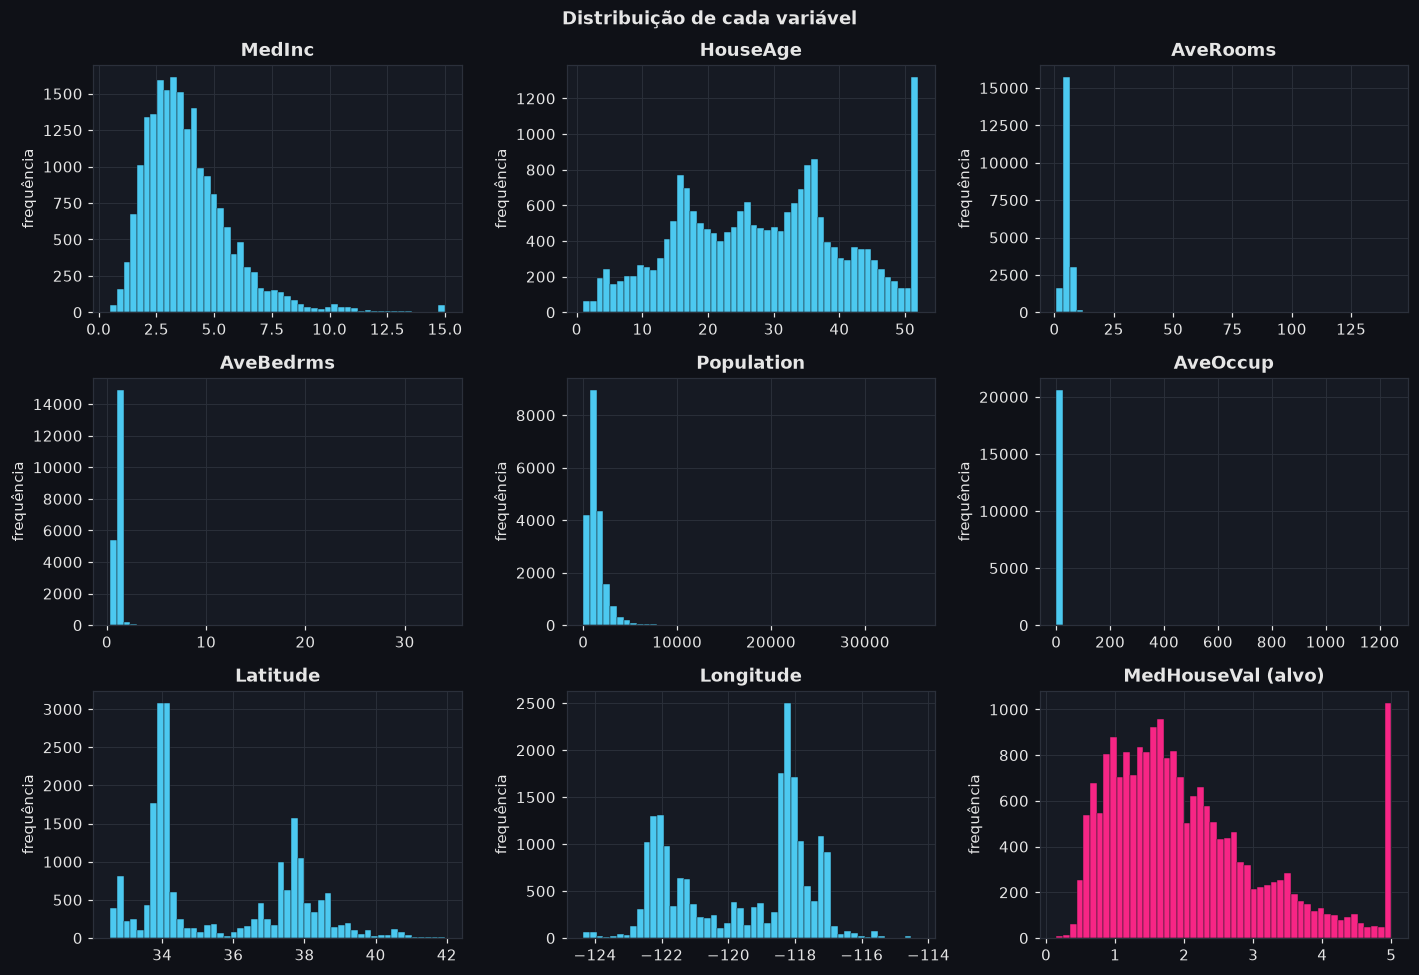

In [21]:
fig, eixos = plt.subplots(3, 3, figsize=(13, 9))
for ax, coluna in zip(eixos.ravel(), df_casas.columns):
    cor = ROSA if coluna == "MedHouseVal" else AZUL
    ax.hist(df_casas[coluna], bins=50, color=cor, edgecolor=PAINEL, linewidth=0.3)
    ax.set_title(coluna + (" (alvo)" if coluna == "MedHouseVal" else ""))
    ax.set_ylabel("frequência")
    ax.locator_params(axis="x", nbins=7)
fig.suptitle("Distribuição de cada variável", fontweight="bold")
plt.tight_layout()
plt.show()

In [22]:
# Quantos quarteirões estão exatamente no valor máximo do alvo?
teto = df_casas["MedHouseVal"].max()
no_teto = (df_casas["MedHouseVal"] == teto).sum()
print(f"Valor máximo do alvo: {teto:.5f} (US$ {teto * 100_000:,.0f})")
print(f"Quarteirões exatamente nesse valor: {no_teto} ({no_teto / len(df_casas):.1%} do total)")

Valor máximo do alvo: 5.00001 (US$ 500,001)
Quarteirões exatamente nesse valor: 965 (4.7% do total)


Os histogramas confirmam o que a tabela sugeria:

- **O alvo é censurado no topo.** 965 quarteirões (4,7%) têm exatamente o valor 5,00001. No censo, qualquer valor acima de USD 500 mil foi registrado como "500.001", então para esses quarteirões o preço verdadeiro é desconhecido: só sabemos que é *pelo menos* isso. Isso aparece como a barra isolada na ponta direita do histograma do alvo. O mesmo acontece com `HouseAge` em 52 anos (1.273 quarteirões).
- `MedInc` e o alvo são assimétricos à direita, com muitos quarteirões de renda e preço baixos ou médios e uma cauda de quarteirões ricos.
- Os histogramas de `AveRooms`, `AveBedrms`, `Population` e `AveOccup` parecem uma única barra encostada à esquerda. É o efeito dos valores extremos esticando o eixo.
- `Latitude` e `Longitude` têm dois picos cada, que correspondem às duas grandes concentrações urbanas do estado: a região de Los Angeles/San Diego e a região de San Francisco.

### 9.3 Relação das variáveis com o preço

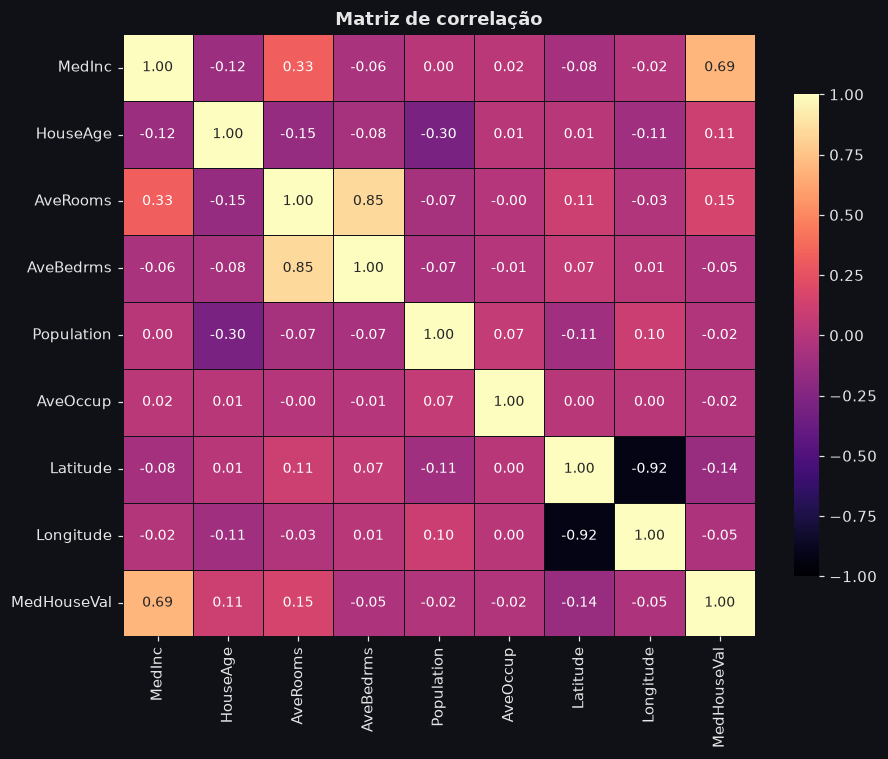

Correlação de cada atributo com o preço:
MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144


In [23]:
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(df_casas.corr(), annot=True, fmt=".2f", cmap="magma", vmin=-1, vmax=1,
            linewidths=0.5, linecolor=FUNDO, annot_kws={"size": 9},
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matriz de correlação")
ax.grid(False)
plt.tight_layout()
plt.show()

print("Correlação de cada atributo com o preço:")
print(df_casas.corr()["MedHouseVal"].drop("MedHouseVal").sort_values(ascending=False).round(3).to_string())

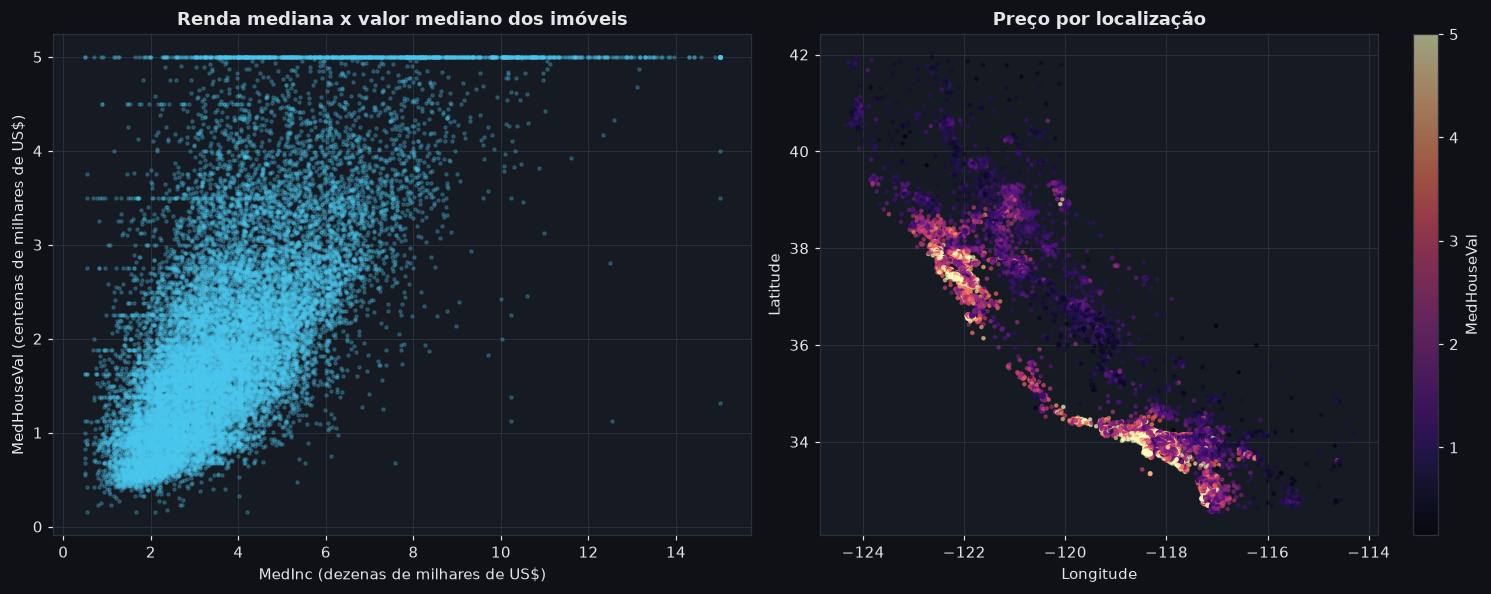

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# renda x preço
ax1.scatter(df_casas["MedInc"], df_casas["MedHouseVal"], s=4, alpha=0.25, color=AZUL)
ax1.set_title("Renda mediana x valor mediano dos imóveis")
ax1.set_xlabel("MedInc (dezenas de milhares de US$)")
ax1.set_ylabel("MedHouseVal (centenas de milhares de US$)")

# mapa: cada ponto é um quarteirão, a cor é o preço
mapa = ax2.scatter(df_casas["Longitude"], df_casas["Latitude"], c=df_casas["MedHouseVal"],
                   cmap="magma", s=4, alpha=0.6)
ax2.set_title("Preço por localização")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
fig.colorbar(mapa, ax=ax2, label="MedHouseVal")

plt.tight_layout()
plt.show()

- **A renda é, de longe, a variável mais relacionada ao preço** (correlação de 0,69). O gráfico de dispersão mostra uma tendência crescente clara, mas com muita dispersão em torno dela: quarteirões com a mesma renda têm preços bem diferentes.
- No mesmo gráfico dá para ver a **linha horizontal no topo**, em 5,0, formada pelos quarteirões com preço censurado. Uma reta não tem como reproduzir esse corte.
- As outras variáveis têm correlação linear fraca com o preço: `AveRooms` 0,15, `Latitude` -0,14, `HouseAge` 0,11 e as demais perto de zero.
- **A localização importa muito, mas não de forma linear.** No mapa, os quarteirões caros (claros) se concentram no litoral, em torno de San Francisco e de Los Angeles, e o interior é mais barato. A correlação baixa de latitude e longitude com o preço não significa que elas sejam irrelevantes; significa que a relação não é uma reta. "Estar perto do mar" ou "estar perto de uma grande cidade" não é algo que um coeficiente multiplicando a latitude consiga expressar.
- `Latitude` e `Longitude` são fortemente correlacionadas entre si (-0,92), porque a Califórnia é um estado inclinado: quanto mais ao norte, mais a oeste. `AveRooms` e `AveBedrms` também (0,85).

A expectativa, portanto, é que a Regressão Linear capture bem o efeito da renda e apenas parte do efeito da localização.

## 10. Pré-processamento

- **Variável dependente (y):** `MedHouseVal`, o valor mediano dos imóveis do quarteirão.
- **Variáveis independentes (X):** as outras oito colunas.
- **Divisão:** 80% treino e 20% teste, com a mesma semente da Parte 1.
- **Padronização:** a Regressão Linear por mínimos quadrados faz exatamente as mesmas previsões com ou sem padronização. Mesmo assim padronizo (dentro do *pipeline*, ajustando só no treino) porque isso deixa os coeficientes na mesma unidade, "variação no preço para um desvio padrão a mais na variável", e permite comparar a importância de cada uma.
- **Outliers e valores no teto:** decidi **não remover nada**. O objetivo é avaliar a Regressão Linear nos dados como eles são, e remover linhas com base no alvo deixaria as métricas artificialmente melhores. O efeito dessas características aparece na avaliação e é discutido lá.

In [25]:
X_casas = df_casas.drop(columns="MedHouseVal")
y_casas = df_casas["MedHouseVal"]

X_treino_r, X_teste_r, y_treino_r, y_teste_r = train_test_split(
    X_casas, y_casas, test_size=0.20, random_state=SEED
)

print(f"Treino: {X_treino_r.shape[0]} quarteirões")
print(f"Teste : {X_teste_r.shape[0]} quarteirões")

Treino: 16512 quarteirões
Teste : 4128 quarteirões


## 11. Treinamento do modelo

In [26]:
modelo_casas = make_pipeline(StandardScaler(), LinearRegression())
modelo_casas.fit(X_treino_r, y_treino_r)

regressao = modelo_casas[-1]
coeficientes_r = pd.Series(regressao.coef_, index=X_casas.columns).sort_values(key=abs, ascending=False)

print(f"Intercepto: {regressao.intercept_:.4f}  (preço previsto para um quarteirão 'médio' em tudo)")
print("\nCoeficientes (efeito de +1 desvio padrão em cada variável):")
print(coeficientes_r.round(4).to_string())

Intercepto: 2.0719  (preço previsto para um quarteirão 'médio' em tudo)

Coeficientes (efeito de +1 desvio padrão em cada variável):
Latitude     -0.897
Longitude    -0.870
MedInc        0.854
AveBedrms     0.339
AveRooms     -0.294
HouseAge      0.122
AveOccup     -0.041
Population   -0.002


## 12. Avaliação dos resultados

In [27]:
def metricas_regressao(y_real, y_previsto):
    mse = mean_squared_error(y_real, y_previsto)
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_previsto),
    }

pred_treino_r = modelo_casas.predict(X_treino_r)
pred_teste_r = modelo_casas.predict(X_teste_r)

metricas_r = pd.DataFrame({
    "treino": metricas_regressao(y_treino_r, pred_treino_r),
    "teste": metricas_regressao(y_teste_r, pred_teste_r),
})
display(metricas_r.style.format("{:.4f}"))

# o alvo está em centenas de milhares de dólares, então converto para ficar concreto
print(f"MAE  no teste em dólares: US$ {metricas_r.loc['MAE', 'teste'] * 100_000:,.0f}")
print(f"RMSE no teste em dólares: US$ {metricas_r.loc['RMSE', 'teste'] * 100_000:,.0f}")
print(f"Preço médio no teste    : US$ {y_teste_r.mean() * 100_000:,.0f}")

,treino,teste
MAE,0.5286,0.5332
MSE,0.5179,0.5559
RMSE,0.7197,0.7456
R²,0.6126,0.5758


MAE  no teste em dólares: US$ 53,320
RMSE no teste em dólares: US$ 74,558
Preço médio no teste    : US$ 205,500


In [28]:
# Duas referências para saber se esses números são bons ou ruins:
# 1) prever sempre a média do treino; 2) estabilidade do R² em validação cruzada
pred_media = np.full(len(y_teste_r), y_treino_r.mean())
print(f"MAE prevendo sempre a média do treino: {mean_absolute_error(y_teste_r, pred_media):.4f}")
print(f"RMSE prevendo sempre a média do treino: {np.sqrt(mean_squared_error(y_teste_r, pred_media)):.4f}")

cv_r = KFold(n_splits=5, shuffle=True, random_state=SEED)
r2_cv = cross_val_score(modelo_casas, X_treino_r, y_treino_r, cv=cv_r, scoring="r2")
print(f"\nR² em validação cruzada (5 partes, só treino): {r2_cv.round(4)}")
print(f"Média: {r2_cv.mean():.4f} | desvio padrão: {r2_cv.std():.4f}")

MAE prevendo sempre a média do treino: 0.9061
RMSE prevendo sempre a média do treino: 1.1449

R² em validação cruzada (5 partes, só treino): [0.6097 0.6041 0.6354 0.6008 0.6073]
Média: 0.6115 | desvio padrão: 0.0124


### 12.1 Valores reais x valores previstos

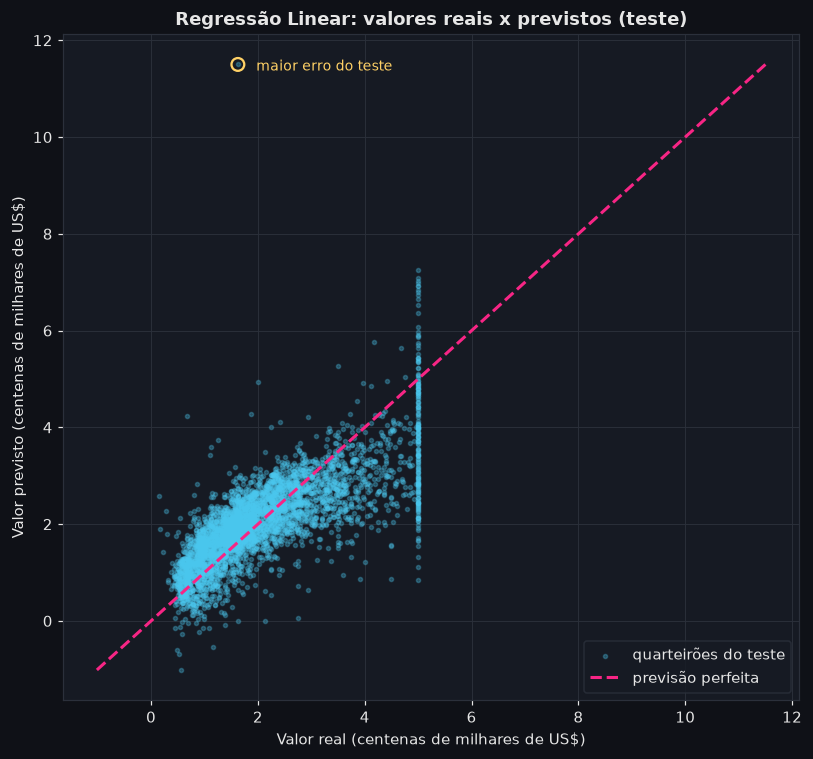

In [29]:
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_teste_r, pred_teste_r, s=7, alpha=0.3, color=AZUL, label="quarteirões do teste")

limites = [min(y_teste_r.min(), pred_teste_r.min()), max(y_teste_r.max(), pred_teste_r.max())]
ax.plot(limites, limites, color=ROSA, linewidth=2, linestyle="--", label="previsão perfeita")

# destaco a previsão mais distante do valor real, que é discutida mais abaixo
i_pior = np.abs(y_teste_r.values - pred_teste_r).argmax()
ax.scatter(y_teste_r.iloc[i_pior], pred_teste_r[i_pior], s=70, facecolors="none",
           edgecolors=AMARELO, linewidths=1.5)
ax.annotate("maior erro do teste", (y_teste_r.iloc[i_pior], pred_teste_r[i_pior]),
            xytext=(12, -4), textcoords="offset points", color=AMARELO, fontsize=9)

ax.set_title("Regressão Linear: valores reais x previstos (teste)")
ax.set_xlabel("Valor real (centenas de milhares de US$)")
ax.set_ylabel("Valor previsto (centenas de milhares de US$)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

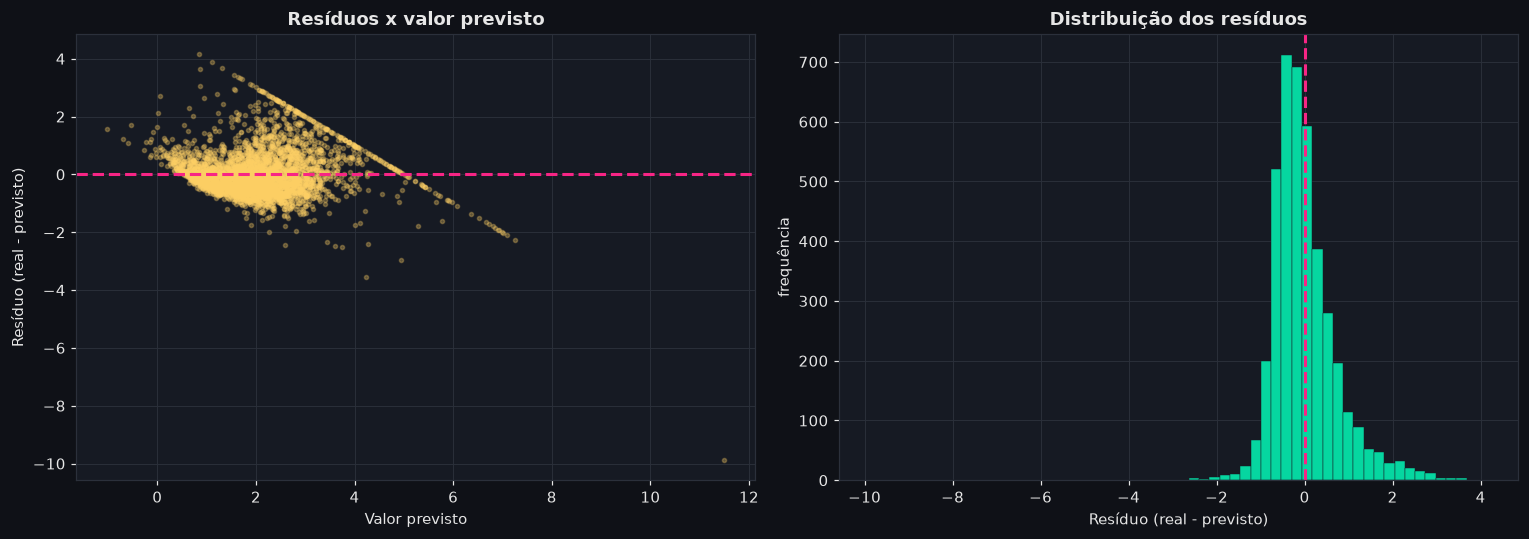

In [30]:
# Resíduos = real - previsto. Positivo significa que o modelo previu menos que o real.
residuos = y_teste_r - pred_teste_r

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(pred_teste_r, residuos, s=7, alpha=0.3, color=AMARELO)
ax1.axhline(0, color=ROSA, linewidth=2, linestyle="--")
ax1.set_title("Resíduos x valor previsto")
ax1.set_xlabel("Valor previsto")
ax1.set_ylabel("Resíduo (real - previsto)")

ax2.hist(residuos, bins=60, color=VERDE, edgecolor=PAINEL, linewidth=0.3)
ax2.axvline(0, color=ROSA, linewidth=2, linestyle="--")
ax2.set_title("Distribuição dos resíduos")
ax2.set_xlabel("Resíduo (real - previsto)")
ax2.set_ylabel("frequência")

plt.tight_layout()
plt.show()

In [31]:
# Alguns números para apoiar a leitura dos gráficos
teto_teste = y_teste_r >= teto
faixas = pd.cut(y_teste_r, bins=[0, 1, 2, 3, 4, 5.1],
                labels=["até 100 mil", "100-200 mil", "200-300 mil", "300-400 mil", "acima de 400 mil"])
erro_por_faixa = pd.DataFrame({
    "quarteirões": faixas.value_counts().sort_index(),
    "erro médio (real - previsto)": residuos.groupby(faixas, observed=True).mean(),
    "MAE": residuos.abs().groupby(faixas, observed=True).mean(),
})
display(erro_por_faixa)

print(f"Previsões negativas no teste          : {(pred_teste_r < 0).sum()}")
print(f"Previsões acima do teto de {teto:.2f}       : {(pred_teste_r > teto).sum()}")
print(f"Maior previsão                        : {pred_teste_r.max():.2f}")
print(f"Quarteirões do teste no teto          : {teto_teste.sum()}")
print(f"Erro médio nesses quarteirões no teto : {residuos[teto_teste].mean():.3f}")
print(f"Previsões com erro de até 50 mil US$  : {(residuos.abs() <= 0.5).mean():.1%}")

,quarteirões,erro médio (real - previsto),MAE
MedHouseVal,,,
até 100 mil,739,-0.310,0.444
100-200 mil,1682,-0.284,0.432
200-300 mil,956,0.044,0.382
300-400 mil,412,0.670,0.738
acima de 400 mil,339,1.191,1.410


Previsões negativas no teste          : 15
Previsões acima do teto de 5.00       : 39
Maior previsão                        : 11.50
Quarteirões do teste no teto          : 179
Erro médio nesses quarteirões no teto : 1.128
Previsões com erro de até 50 mil US$  : 58.7%


### 12.2 Interpretação dos resultados

**As métricas, em termos concretos (conjunto de teste):**

| Métrica | Valor | O que significa |
|---|---|---|
| MAE | 0,533 | em média, a previsão erra o valor do quarteirão em cerca de USD 53 mil, para um preço médio de USD 205 mil (aproximadamente 26%) |
| MSE | 0,556 | erro quadrático médio; está em "unidades ao quadrado", então serve mais para comparar modelos do que para interpretar |
| RMSE | 0,746 | cerca de USD 75 mil. É bem maior que o MAE porque penaliza mais os erros grandes, sinal de que existem previsões muito ruins |
| R² | 0,576 | o modelo explica cerca de 58% da variação dos preços; os outros 42% ficam sem explicação |

**É melhor do que não ter modelo?** Sim. Prever sempre a média do treino daria MAE de 0,906 e RMSE de 1,145. A Regressão Linear reduz o MAE em cerca de 41% e o RMSE em cerca de 35%.

**Há sobreajuste?** Não. Treino e teste têm erros muito parecidos (MAE 0,529 contra 0,533). O problema aqui é o oposto: **subajuste**. O modelo é simples demais para os dados, e nem no próprio treino consegue passar de R² = 0,61.

**Por que o R² do teste (0,576) ficou abaixo da validação cruzada (0,61 ± 0,01)?** A diferença vem quase toda de um único quarteirão do teste, analisado na célula abaixo.

In [32]:
# O quarteirão do teste com o maior erro
pior = residuos.abs().idxmax()
linha = X_teste_r.loc[[pior]].assign(real=y_teste_r.loc[pior],
                                     previsto=pred_teste_r[y_teste_r.index.get_loc(pior)])
display(linha)

erro_quadratico = residuos ** 2
sem_pior = y_teste_r.index != pior
print(f"Parcela do erro quadrático total do teste vinda desse quarteirão: {erro_quadratico.loc[pior] / erro_quadratico.sum():.1%}")
print(f"R² no teste com todos os quarteirões : {r2_score(y_teste_r, pred_teste_r):.4f}")
print(f"R² no teste sem esse quarteirão      : {r2_score(y_teste_r[sem_pior], pred_teste_r[sem_pior]):.4f}")
print(f"MAE no teste sem esse quarteirão     : {mean_absolute_error(y_teste_r[sem_pior], pred_teste_r[sem_pior]):.4f}")
print(f"Mediana dos resíduos                 : {residuos.median():.3f}")
print(f"Previsões para os quarteirões no teto: de {pred_teste_r[teto_teste].min():.2f} a {pred_teste_r[teto_teste].max():.2f}")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,real,previsto
1979,4.625,34.000,132.533,34.067,36.000,2.400,38.800,-120.080,1.625,11.500


Parcela do erro quadrático total do teste vinda desse quarteirão: 4.2%
R² no teste com todos os quarteirões : 0.5758
R² no teste sem esse quarteirão      : 0.5938
MAE no teste sem esse quarteirão     : 0.5309
Mediana dos resíduos                 : -0.122
Previsões para os quarteirões no teto: de 0.85 a 7.26


Esse quarteirão tem média de 132,5 cômodos por domicílio (pelas coordenadas fica na Sierra Nevada, perto do lago Tahoe, provavelmente uma área de hotéis ou casas de temporada). O modelo previu 11,50 (USD 1,15 milhão) para um valor real de 1,63. Sozinho, ele responde por cerca de 4% de todo o erro quadrático do teste, e sem ele o R² sobe de 0,576 para 0,594. É um exemplo concreto de como a Regressão Linear extrapola sem limite quando encontra um valor extremo, e de como MSE, RMSE e R² são sensíveis a poucos pontos. O MAE quase não se altera com esse caso, por isso considero o MAE a medida mais representativa do erro típico aqui.

**O que os gráficos mostram:**

- **Real x previsto:** os pontos acompanham a diagonal, mas formando uma nuvem larga. Para imóveis baratos a nuvem fica acima da diagonal (o modelo superestima) e para os caros fica abaixo (subestima).
- **A faixa vertical à direita, em 5,0,** são os quarteirões com preço censurado. O modelo espalha as previsões deles entre 0,9 e 7,3, errando em média 1,13 para baixo (USD 113 mil). Parte desse erro nem é culpa do modelo: o valor real registrado é que está truncado.
- **A tabela por faixa de preço** quantifica o viés: até USD 200 mil o modelo superestima em torno de USD 30 mil; entre 200 e 300 mil praticamente não tem viés; acima de 400 mil subestima em média USD 119 mil, com MAE de USD 141 mil. O modelo funciona razoavelmente no meio da distribuição e mal nas pontas.
- **Resíduos:** se o modelo linear fosse adequado, os resíduos seriam uma nuvem sem forma em torno de zero. O que aparece é uma estrutura clara, incluindo uma linha diagonal (efeito do teto de 5,0) e uma cauda longa de resíduos positivos. O histograma é assimétrico: a mediana do resíduo é negativa (-0,12) e a cauda direita é mais comprida.
- **Previsões impossíveis:** 15 quarteirões do teste receberam preço **negativo** e 39 receberam valor acima do teto. Nada no modelo linear impede isso.

**Sobre os coeficientes.** Como os dados foram padronizados, cada coeficiente é o efeito de um desvio padrão a mais naquela variável:

- `MedInc` (+0,85): um desvio padrão a mais de renda (cerca de USD 19 mil) está associado a USD 85 mil a mais no valor do imóvel, mantidas as outras variáveis. É o efeito mais fácil de interpretar e o mais confiável.
- `Latitude` (-0,90) e `Longitude` (-0,87): têm os maiores coeficientes em módulo, apesar da correlação fraca com o preço quando analisadas sozinhas. Juntas, elas descrevem um plano inclinado que barateia os imóveis conforme se vai para o norte e para o leste, isto é, para longe do litoral. É a forma que a reta encontrou de aproximar a ideia de "distância do mar".
- `AveRooms` (-0,29) e `AveBedrms` (+0,34): os sinais parecem contraintuitivos (mais cômodos, menor preço?), mas as duas são muito correlacionadas entre si e com a renda. Com a renda já no modelo, o que sobra para elas explicar é pouco e os sinais não devem ser interpretados isoladamente.
- `Population` e `AveOccup` têm efeito praticamente nulo.

**Resumo.** A Regressão Linear dá uma estimativa razoável de ordem de grandeza (59% das previsões ficam a menos de USD 50 mil do valor real), baseada principalmente na renda e em uma aproximação grosseira da localização. Ela não serve para uma avaliação precisa de imóveis, e erra de forma sistemática justamente nos quarteirões mais baratos e nos mais caros.

---

# 13. Conclusão

Os dois problemas foram resolvidos com o mesmo roteiro e com modelos lineares, mas os resultados foram bem diferentes, e a comparação entre eles é a parte mais instrutiva do trabalho.

### Classificação (câncer de mama)

A Regressão Logística atingiu **96,5% de *accuracy*, 97,5% de *precision*, 92,9% de *recall* e 95,1% de F1** para a classe maligna no conjunto de teste, contra um piso de 62,7% de quem sempre responde "benigno". O resultado do teste é coerente com a validação cruzada e não há sinal de sobreajuste.

O resultado é bom, mas não deve ser lido com otimismo demais:

- O modelo deixou passar **3 dos 42 tumores malignos**. Em um problema em que o falso negativo é o erro mais grave, o *recall* de 92,9% é a métrica que deveria orientar qualquer melhoria, não a *accuracy*.
- Um desses casos recebeu apenas 6% de probabilidade de ser maligno, então ajustar o limiar de decisão ajudaria, mas não resolveria tudo.
- O teste tem só 114 exames. Um único exame muda o *recall* em 2,4 pontos, de modo que os números têm uma margem de incerteza grande.
- Na validação cruzada, Regressão Logística, Random Forest e KNN ficaram praticamente empatados. A escolha foi por simplicidade e interpretabilidade, não porque um deles seja comprovadamente melhor.
- Os dados vêm de um único hospital e de uma única técnica de exame. Nada aqui garante que o desempenho se manteria com pacientes e equipamentos de outro lugar.

O modelo seria útil como apoio à triagem, sinalizando casos para revisão, e não como substituto do diagnóstico médico.

### Regressão (preços de imóveis)

A Regressão Linear obteve **MAE = 0,533 (cerca de USD 53 mil), MSE = 0,556, RMSE = 0,746 (cerca de USD 75 mil) e R² = 0,576** no teste. É claramente melhor do que prever a média (MAE 41% menor), mas explica pouco mais da metade da variação dos preços e erra em média 26% do valor de um imóvel típico.

Aqui o problema não é sobreajuste, e sim um modelo simples demais para o fenômeno:

- o preço depende da localização de uma forma que não é linear (proximidade do litoral e das grandes cidades), e latitude e longitude entram no modelo apenas como um plano inclinado;
- o alvo é censurado em USD 500 mil, o que faz o modelo subestimar sistematicamente os quarteirões mais caros (em média USD 119 mil acima de 400 mil);
- valores extremos em variáveis como `AveRooms` levam a previsões absurdas, e um único quarteirão do teste foi suficiente para derrubar o R² em quase 2 pontos;
- o modelo produziu 15 previsões de preço negativo, algo que não faz sentido.

Além disso, os dados são do censo de 1990 e agregados por quarteirão. O modelo descreve relações daquela época entre renda, localização e valor mediano, e não serve para precificar um imóvel específico hoje.

### Comparando os dois

A mesma família de modelo funcionou muito bem em um caso e apenas razoavelmente no outro, e a análise exploratória já indicava isso antes do treinamento: no dataset de câncer, as classes aparecem bem separadas em vários atributos, e uma fronteira linear é suficiente; no de imóveis, só a renda tem relação linear forte com o preço, e o mapa mostra um padrão geográfico que uma reta não consegue representar. A qualidade do resultado dependeu mais de o modelo combinar com a estrutura dos dados do que do algoritmo em si.

Também ficou claro que nenhuma métrica sozinha conta a história toda. Na classificação, a *accuracy* de 96,5% esconde que os erros se concentram no tipo mais perigoso. Na regressão, o R² e o RMSE foram distorcidos por um único ponto, enquanto o MAE por faixa de preço mostrou onde o modelo de fato falha.

### O que eu faria em seguida

- **Classificação:** escolher o limiar de decisão por validação cruzada priorizando *recall*, e avaliar com validação cruzada repetida para ter intervalos de confiança em vez de um único número.
- **Regressão:** tratar os valores extremos (limitar ou aplicar logaritmo em `AveRooms`, `AveBedrms`, `AveOccup` e `Population`), prever o logaritmo do preço para evitar valores negativos, criar variáveis de localização mais informativas (como distância ao litoral) e comparar com um modelo não linear, como Random Forest ou Gradient Boosting, usando a Regressão Linear deste trabalho como referência.